1. Java, Hadoop, HDFS setup aur daemons start

In [1]:
import os, subprocess

!apt-get install -y -q openjdk-17-jdk-headless > /dev/null 2>&1
!pip install -q pyspark

HADOOP = "/content/hadoop-3.3.6"
TAR = "/content/hadoop-3.3.6.tar.gz"
if not os.path.exists(f"{HADOOP}/bin/hadoop"):
    !wget -q --tries=5 -c https://archive.apache.org/dist/hadoop/common/hadoop-3.3.6/hadoop-3.3.6.tar.gz -O {TAR}
    !rm -rf {HADOOP}
    !tar -xzf {TAR} -C /content/

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["HADOOP_HOME"] = HADOOP
os.environ["PATH"] = f"{os.environ['JAVA_HOME']}/bin:{HADOOP}/bin:{HADOOP}/sbin:" + os.environ["PATH"]
os.environ["HDFS_NAMENODE_USER"] = "root"
os.environ["HDFS_DATANODE_USER"] = "root"
os.environ["HDFS_SECONDARYNAMENODE_USER"] = "root"

conf = f"{HADOOP}/etc/hadoop"
with open(f"{conf}/core-site.xml", "w") as f:
    f.write("<configuration><property><name>fs.defaultFS</name><value>hdfs://localhost:9000</value></property></configuration>")
with open(f"{conf}/hdfs-site.xml", "w") as f:
    f.write("<configuration><property><name>dfs.replication</name><value>1</value></property><property><name>dfs.namenode.name.dir</name><value>file:///content/hdfs/namenode</value></property><property><name>dfs.datanode.data.dir</name><value>file:///content/hdfs/datanode</value></property></configuration>")
with open(f"{conf}/hadoop-env.sh", "a") as f:
    f.write("\nexport JAVA_HOME=/usr/lib/jvm/java-17-openjdk-amd64\nexport HDFS_NAMENODE_USER=root\nexport HDFS_DATANODE_USER=root\nexport HDFS_SECONDARYNAMENODE_USER=root\n")

!rm -rf /content/hdfs
!hdfs namenode -format -force -nonInteractive > /tmp/format.log 2>&1
!hdfs --daemon start namenode
!hdfs --daemon start datanode
time.sleep(10) if False else None
import time; time.sleep(10)
!jps

12324 DataNode
12263 NameNode
12494 Jps


2. CSV upload

In [2]:
import os, glob
!hdfs dfs -mkdir -p /fraud/raw/paysim
for f in glob.glob("/content/PS_*.csv"):
    if os.path.getsize(f) == 493534783:
        !hdfs dfs -put -f "{f}" /fraud/raw/paysim/
        !hdfs dfs -stat "HDFS bytes: %b" /fraud/raw/paysim/PS_20174392719_1491204439457_log.csv
        !hdfs dfs -cat /fraud/raw/paysim/PS_20174392719_1491204439457_log.csv | wc -l
        break
else:
    print("Sahi size wali file /content/ mein nahi mili. Upload dobara karo.")

HDFS bytes: 493534783
6362621


3. Spark se HDFS data load aur row count

In [3]:
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["HADOOP_HOME"] = "/content/hadoop-3.3.6"
os.environ["PATH"] = f"{os.environ['JAVA_HOME']}/bin:{os.environ['HADOOP_HOME']}/bin:{os.environ['HADOOP_HOME']}/sbin:" + os.environ["PATH"]

from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window
import pandas as pd

spark = (SparkSession.builder.appName("BankFraudHDFS").master("local[*]")
         .config("spark.hadoop.fs.defaultFS", "hdfs://localhost:9000")
         .config("spark.sql.shuffle.partitions", "8")
         .enableHiveSupport().getOrCreate())
spark.sparkContext.setLogLevel("WARN")

df = spark.read.csv("hdfs://localhost:9000/fraud/raw/paysim/PS_20174392719_1491204439457_log.csv",
                    header=True, inferSchema=True)
print("Rows from HDFS:", df.count())
df.printSchema()

Rows from HDFS: 6362620
root
 |-- step: integer (nullable = true)
 |-- type: string (nullable = true)
 |-- amount: double (nullable = true)
 |-- nameOrig: string (nullable = true)
 |-- oldbalanceOrg: double (nullable = true)
 |-- newbalanceOrig: double (nullable = true)
 |-- nameDest: string (nullable = true)
 |-- oldbalanceDest: double (nullable = true)
 |-- newbalanceDest: double (nullable = true)
 |-- isFraud: integer (nullable = true)
 |-- isFlaggedFraud: integer (nullable = true)



4. Hive-style table aur SQL query



In [4]:
spark.sql("CREATE DATABASE IF NOT EXISTS fraud")
spark.sql("DROP TABLE IF EXISTS fraud.transactions")
spark.sql("""
CREATE TABLE fraud.transactions
USING csv
OPTIONS (header 'true', inferSchema 'true', path 'hdfs://localhost:9000/fraud/raw/paysim')
""")

print("Table rows:", spark.table("fraud.transactions").count())
spark.sql("""
SELECT type, COUNT(*) AS total, SUM(isFraud) AS fraud_count
FROM fraud.transactions
GROUP BY type
ORDER BY fraud_count DESC
""").show()

Table rows: 6362620
+--------+-------+-----------+
|    type|  total|fraud_count|
+--------+-------+-----------+
|CASH_OUT|2237500|       4116|
|TRANSFER| 532909|       4097|
| PAYMENT|2151495|          0|
|   DEBIT|  41432|          0|
| CASH_IN|1399284|          0|
+--------+-------+-----------+



 5. Fraud patterns (p1 se p4) aur evaluation

In [5]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import pandas as pd

d = (spark.table("fraud.transactions")
     .dropna(subset=["step", "amount", "nameOrig"]).dropDuplicates()
     .withColumn("hour_of_day", F.col("step") % 24))

cities = ["Delhi", "Mumbai", "Bengaluru", "Kolkata", "Chennai", "Hyderabad", "Pune", "Jaipur"]
n = len(cities)
city_arr = F.array(*[F.lit(c) for c in cities])
d = d.withColumn("home_city", F.element_at(city_arr, (F.abs(F.hash("nameOrig")) % n + 1).cast("int")))
other = F.element_at(city_arr, (F.abs(F.hash("nameDest")) % n + 1).cast("int"))
rnd = F.rand(seed=42)
d = d.withColumn("city",
        F.when((F.col("isFraud") == 1) & (rnd < 0.4), other)
         .when((F.col("isFraud") == 0) & (rnd < 0.05), other)
         .otherwise(F.col("home_city")))
rnd2 = F.rand(seed=7)
d = d.withColumn("status",
        F.when(((F.col("isFraud") == 1) & (rnd2 < 0.35)) |
               ((F.col("isFraud") == 0) & (rnd2 < 0.03)), "FAILED")
         .otherwise("SUCCESS"))

d = (d.withColumn("type_p99", F.percentile_approx("amount", 0.99).over(Window.partitionBy("type")))
       .withColumn("p1_high_value", F.when(F.col("amount") > F.col("type_p99"), 1).otherwise(0)))

city_hour = (d.groupBy("city", "step")
               .agg(F.sum(F.when(F.col("status") == "FAILED", 1).otherwise(0)).alias("failed_city_hr")))
thr = city_hour.approxQuantile("failed_city_hr", [0.95], 0.01)[0]
d = (d.join(F.broadcast(city_hour), on=["city", "step"], how="left")
       .withColumn("p2_failed_attempts", F.when(F.col("failed_city_hr") >= thr, 1).otherwise(0)))

d = d.withColumn("p3_location", F.when(F.col("city") != F.col("home_city"), 1).otherwise(0))

drain = ((F.col("type").isin("TRANSFER", "CASH_OUT")) & (F.col("oldbalanceOrg") > 0) &
         (F.col("newbalanceOrig") == 0) & (F.col("amount") > 100000))
night_big = F.col("hour_of_day").between(1, 4) & (F.col("amount") > 200000)
d = d.withColumn("p4_suspicious", F.when(drain | night_big, 1).otherwise(0))

patterns = ["p1_high_value", "p2_failed_attempts", "p3_location", "p4_suspicious"]
d = d.withColumn("any_flag", F.when(sum(F.col(p) for p in patterns) > 0, 1).otherwise(0))
df = d.cache()

print("Total rows:", df.count(), "| burst threshold:", thr)
for p in patterns:
    print(p, "flagged:", df.filter(F.col(p) == 1).count())

total_fraud = df.filter("isFraud = 1").count()
rows = []
for p in patterns + ["any_flag"]:
    tp = df.filter((F.col(p) == 1) & (F.col("isFraud") == 1)).count()
    fp = df.filter((F.col(p) == 1) & (F.col("isFraud") == 0)).count()
    fn = total_fraud - tp
    prec = tp / (tp + fp) if (tp + fp) else 0
    rec = tp / total_fraud
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0
    rows.append((p, tp, fp, fn, round(prec, 4), round(rec, 4), round(f1, 4)))

ev = pd.DataFrame(rows, columns=["pattern", "TP", "FP", "FN", "precision", "recall", "f1"])
print(ev.to_string(index=False))
spark.createDataFrame(ev).coalesce(1).write.mode("overwrite").option("header", True) \
     .csv("hdfs://localhost:9000/fraud/output/pattern_evaluation")

Total rows: 6362620 | burst threshold: 139.0
p1_high_value flagged: 60884
p2_failed_attempts flagged: 1616953
p3_location flagged: 280971
p4_suspicious flagged: 940936
           pattern   TP      FP   FN  precision  recall     f1
     p1_high_value 1806   59078 6407     0.0297  0.2199 0.0523
p2_failed_attempts  440 1616513 7773     0.0003  0.0536 0.0005
       p3_location 2830  278141 5383     0.0101  0.3446 0.0196
     p4_suspicious 6354  934582 1859     0.0068  0.7737 0.0134
          any_flag 7095 2526627 1118     0.0028  0.8639 0.0056


6a. Logistic Regression model

In [6]:
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator

fraud = df.filter("isFraud = 1")
normal = df.filter("isFraud = 0").sample(fraction=0.1, seed=42)
ml = fraud.unionByName(normal).withColumn("label", F.col("isFraud").cast("double"))

ml = StringIndexer(inputCol="type", outputCol="type_idx", handleInvalid="keep").fit(ml).transform(ml)

n_neg = ml.filter("label = 0").count()
n_pos = ml.filter("label = 1").count()
ml = ml.withColumn("w", F.when(F.col("label") == 1, F.lit(n_neg / n_pos)).otherwise(F.lit(1.0)))

feats = ["type_idx", "amount", "oldbalanceOrg", "newbalanceOrig",
         "oldbalanceDest", "newbalanceDest", "p1_high_value", "p4_suspicious"]
ml = VectorAssembler(inputCols=feats, outputCol="features").transform(ml)

train, test = ml.randomSplit([0.8, 0.2], seed=42)
model = LogisticRegression(featuresCol="features", labelCol="label",
                           weightCol="w", maxIter=50).fit(train)
pred = model.transform(test)

 6b. Logistic Regression ke metrics (TP, FP, Precision, Recall, PR-AUC)

In [8]:
tp = pred.filter("label = 1 AND prediction = 1").count()
fp = pred.filter("label = 0 AND prediction = 1").count()
fn = pred.filter("label = 1 AND prediction = 0").count()
precision = tp / (tp + fp) if (tp + fp) else 0
recall = tp / (tp + fn) if (tp + fn) else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0
pr_auc = BinaryClassificationEvaluator(labelCol="label", rawPredictionCol="rawPrediction",
                                       metricName="areaUnderPR").evaluate(pred)
print(f"TP={tp} FP={fp} FN={fn}")
print(f"Precision={precision:.4f} Recall={recall:.4f} F1={f1:.4f} PR-AUC={pr_auc:.4f}")

TP=1490 FP=4467 FN=179
Precision=0.2501 Recall=0.8928 F1=0.3908 PR-AUC=0.7401


7. Rule vs ML comparison

In [9]:
rule_pred = pred.withColumn("rule", F.col("p4_suspicious").cast("double"))
rtp = rule_pred.filter("label = 1 AND rule = 1").count()
rfp = rule_pred.filter("label = 0 AND rule = 1").count()
rfn = rule_pred.filter("label = 1 AND rule = 0").count()
rp = rtp / (rtp + rfp) if (rtp + rfp) else 0
rr = rtp / (rtp + rfn) if (rtp + rfn) else 0

comparison = pd.DataFrame([
    ["Rule p4 (test set)", rtp, rfp, rfn, round(rp, 4), round(rr, 4)],
    ["Logistic Regression (test set)", tp, fp, fn, round(precision, 4), round(recall, 4)],
], columns=["method", "TP", "FP", "FN", "precision", "recall"])
print(comparison.to_string(index=False))
comparison.to_csv("/content/model_vs_rule_comparison.csv", index=False)

                        method   TP    FP  FN  precision  recall
            Rule p4 (test set) 1308 18907 361     0.0647  0.7837
Logistic Regression (test set) 1490  4467 179     0.2501  0.8928


 8a. Pattern evaluation: precision aur recall graph

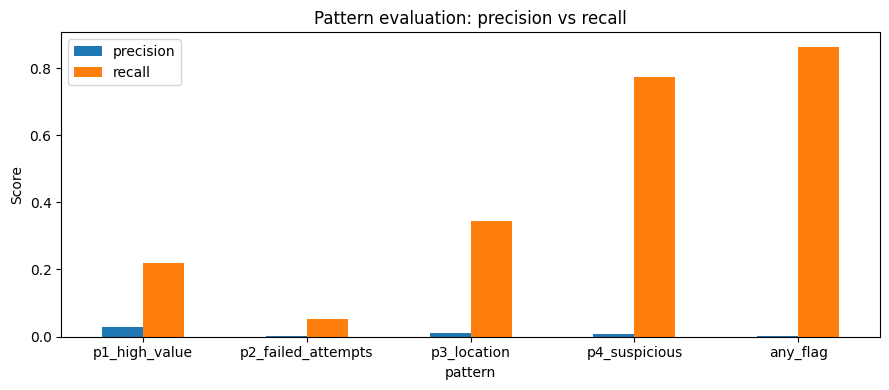

In [10]:
import matplotlib.pyplot as plt
import os

os.makedirs("/content/outputs", exist_ok=True)

ax = ev.set_index("pattern")[["precision", "recall"]].plot.bar(figsize=(9, 4), rot=0)
ax.set_title("Pattern evaluation: precision vs recall")
ax.set_ylabel("Score")
plt.tight_layout()
plt.savefig("/content/outputs/pattern_eval.png", dpi=150)
plt.show()

8b. Fraud rate by hour of day graph

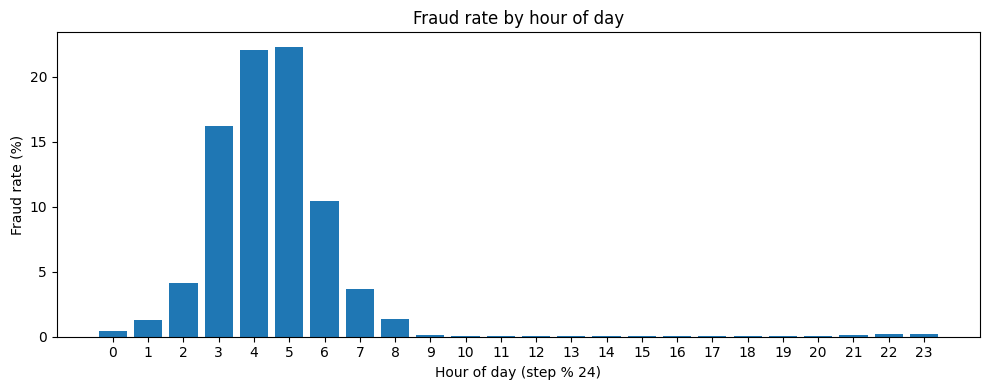

In [11]:
hourly = (df.groupBy("hour_of_day")
            .agg(F.count("*").alias("total"), F.sum("isFraud").alias("fraud"))
            .orderBy("hour_of_day").toPandas())
hourly["fraud_rate_pct"] = hourly["fraud"] / hourly["total"] * 100

plt.figure(figsize=(10, 4))
plt.bar(hourly["hour_of_day"], hourly["fraud_rate_pct"])
plt.xlabel("Hour of day (step % 24)")
plt.ylabel("Fraud rate (%)")
plt.title("Fraud rate by hour of day")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig("/content/outputs/fraud_by_hour.png", dpi=150)
plt.show()